# Subset CMIP6 data by bounding box

**Rooki** calls climate data operations on the **Rook** processing service. For the rectilinear grid in this example, [clisops](https://clisops.readthedocs.io/en/latest/_modules/clisops/core/subset.html#subset_bbox) keeps cells whose longitude and latitude centres are inside or on the requested box. A cell can overlap the box and still be excluded if its centre is outside.

## Request two subsets

Use one day of INM-CM5-0 surface air temperature (`tas`) from the [subset-by-time demo](demo-rooki-subset-by-time.ipynb). Both requests use the same CMIP6 SSP2-4.5 dataset and day. The larger reference box includes neighbouring cells for comparison. Rooki takes `area` in west, south, east, north order, in degrees.

Run this notebook with the Rooki demo environment, Matplotlib and access to a Rook service that serves this collection.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

os.environ['ROOK_URL'] = 'http://rook.dkrz.de/wps'

from rooki import operators as ops

tas = ops.Input(
    "tas",
    ["c3s-cmip6.ScenarioMIP.INM.INM-CM5-0.ssp245.r1i1p1f1.day.tas.gr1.v20190619"],
)
bbox = (6.3, 47.2, 10.4, 50.5)
reference_bbox = (4, 45, 13, 53)


def subset(area):
    area_string = ",".join(map(str, area))
    response = ops.Subset(tas, time="2016-01-01/2016-01-01", area=area_string).orchestrate()
    if not response.ok:
        raise RuntimeError(f"Rook subset failed for {area_string}: {response.status}")
    datasets = response.datasets()
    if len(datasets) != 1:
        raise RuntimeError(f"Expected one downloadable NetCDF file for {area_string}.")
    return datasets[0]


reference = subset(reference_bbox)
selected = subset(bbox)

## Check the returned centres

Use the larger subset to predict which centre coordinates the small request should return. Compare both coordinate axes with the Rook result.

In [2]:
west, south, east, north = bbox
lon = reference.lon.values
lat = reference.lat.values

expected_lon = lon[(west <= lon) & (lon <= east)]
expected_lat = lat[(south <= lat) & (lat <= north)]

np.testing.assert_array_equal(np.sort(selected.lon.values), np.sort(expected_lon))
np.testing.assert_array_equal(np.sort(selected.lat.values), np.sort(expected_lat))
print(f"Rook returned the expected {expected_lon.size * expected_lat.size} grid-cell centres.")

Rook returned the expected 6 grid-cell centres.


## Plot the box and nearby cells

Blue dots mark centres returned by the small request. Grey crosses mark centres found only in the reference request. Orange outlines show excluded cells that overlap the box, using the cell bounds stored in the reference NetCDF. If either bounds variable is missing, the plot shows the centres and the requested box.

3 excluded cells overlap the requested box.


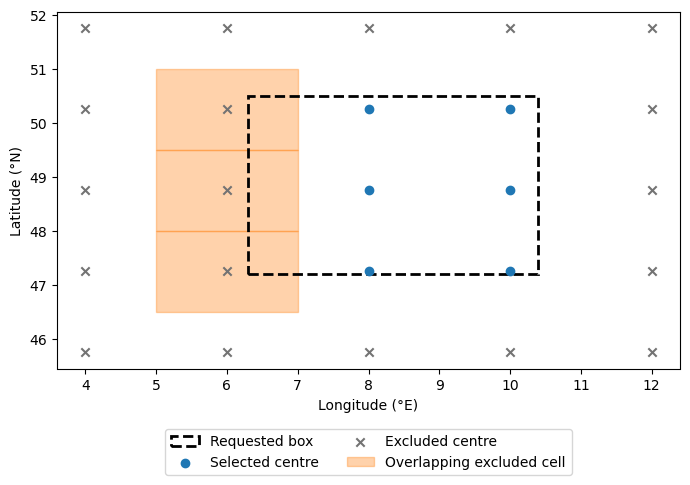

In [3]:
grid_lon, grid_lat = np.meshgrid(lon, lat)
kept = np.isin(grid_lon, selected.lon.values) & np.isin(grid_lat, selected.lat.values)

fig, ax = plt.subplots(figsize=(7, 5))
ax.add_patch(Rectangle(
    (west, south), east - west, north - south,
    fill=False, edgecolor="black", linestyle="--", linewidth=2,
    label="Requested box", zorder=3,
))
ax.scatter(grid_lon[kept], grid_lat[kept], color="tab:blue", label="Selected centre", zorder=4)
ax.scatter(grid_lon[~kept], grid_lat[~kept], color="0.45", marker="x",
           label="Excluded centre", zorder=4)

lon_bounds = reference.get(reference.lon.attrs.get("bounds", "lon_bnds"))
lat_bounds = reference.get(reference.lat.attrs.get("bounds", "lat_bnds"))
if lon_bounds is None or lat_bounds is None:
    print("The reference subset has no usable longitude and latitude bounds pair.")
else:
    cell_west = lon_bounds.min(dim="bnds").values
    cell_east = lon_bounds.max(dim="bnds").values
    cell_south = lat_bounds.min(dim="bnds").values
    cell_north = lat_bounds.max(dim="bnds").values
    overlaps_lon = (cell_west < east) & (cell_east > west)
    overlaps_lat = (cell_south < north) & (cell_north > south)
    rows, cols = np.where(overlaps_lat[:, None] & overlaps_lon & ~kept)

    for index, (row, col) in enumerate(zip(rows, cols)):
        ax.add_patch(Rectangle(
            (cell_west[col], cell_south[row]),
            cell_east[col] - cell_west[col], cell_north[row] - cell_south[row],
            facecolor="tab:orange", edgecolor="tab:orange", alpha=0.35,
            label="Overlapping excluded cell" if index == 0 else None,
        ))
    print(f"{len(rows)} excluded cells overlap the requested box.")

ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.tight_layout()
plt.show()